In [1]:
#very smart bot
#vit - vision transd=former
# by google
#swintransformer by microsoft----latest
#gpt - open AI


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch   #torch ik framework ha deeplearning model ko chalany k lia
import sklearn
import tensorflow as tf
import os
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [3]:
data_path = "/content/drive/MyDrive/Chest_Xray-20261005T080933Z-1-001/earlybrite"
print(os.listdir(data_path))

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [4]:
!pip install transformers accelerator

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.8/103.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 4.9 MB/s eta 0:00:00


In [5]:
#data loader b required -> image loader -
# >choty batches mai convert krns


In [6]:
from torchvision import datasets, transforms
#loader
from torch.utils.data import DataLoader
#auto processor and auto image classifier
from transformers import AutoImageProcessor, AutoModelForImageClassification


In [7]:
#training or testing

In [8]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import random_split
from transformers import AutoImageProcessor

# Initialize the processor directly to avoid NameErrors
model_name = "google/vit-base-patch16-224"
processor = AutoImageProcessor.from_pretrained(model_name)

# Define the transforms using processor values
potato_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(processor.image_mean, processor.image_std)
])

# Load the entire potato dataset with transforms
full_dataset = datasets.ImageFolder(data_path, transform=potato_transform)

# Perform 80/20 train/test split
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

generator = torch.Generator().manual_seed(42)
train_data, test_data = random_split(full_dataset, [train_size, test_size], generator=generator)

# Attach classes back to the subsets for reference
train_data.classes = full_dataset.classes
test_data.classes = full_dataset.classes

print(f"Detected classes: {full_dataset.classes}")
print(f"Total dataset size: {len(full_dataset)}")
print(f"Train dataset size (80%): {len(train_data)}")
print(f"Test dataset size (20%): {len(test_data)}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

Detected classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Total dataset size: 2152
Train dataset size (80%): 1721
Test dataset size (20%): 431


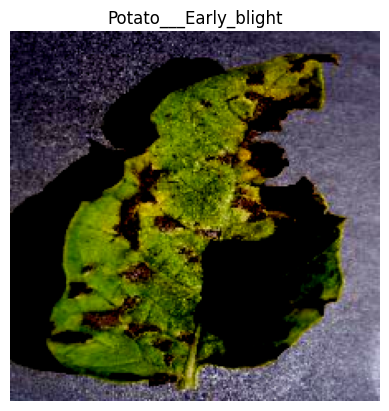

In [9]:
image, label = train_data[0]
from PIL import Image
plt.title(full_dataset.classes[label])
# Use .permute(1, 2, 0) to change shape from (3, 224, 224) to (224, 224, 3) for matplotlib
plt.imshow(image.permute(1, 2, 0))
plt.axis("off")
plt.show()

In [10]:
model_name = "google/vit-base-patch16-224"

processor = AutoImageProcessor.from_pretrained(model_name)

print("Image mean" ,processor.image_mean)

print("standard deviation of image dataset", processor.image_std)

print("image size for transformer", processor.size)



Image mean (0.5, 0.5, 0.5)
standard deviation of image dataset (0.5, 0.5, 0.5)
image size for transformer SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)


In [11]:
# 1. Define image preprocessing transformations for train and test splits
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(processor.image_mean, processor.image_std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(processor.image_mean, processor.image_std)
])

# 2. Assign the defined transforms directly to your existing split datasets
if 'train_data' in globals() and 'test_data' in globals():
    # Apply transforms directly to the underlying datasets
    train_data.dataset.transform = train_transform
    test_data.dataset.transform = test_transform

    print("✓ Transforms successfully applied directly to train_data and test_data!")
    print("Training classes:", train_data.classes)
    print("Testing classes:", test_data.classes)
    print("Training images:", len(train_data))
    print("Testing images:", len(test_data))
else:
    print("✗ Error: 'train_data' and 'test_data' were not found. Please run cell `bmmzrLCcqDn_` first to split your dataset.")

✓ Transforms successfully applied directly to train_data and test_data!
Training classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Testing classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Training images: 1721
Testing images: 431


In [12]:
#dataloader bnana hai-> sari images wo nahi dy skty hain
#to hm isko bacth mai bnaingy -> data loader

#device konsa available hai ? tpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

batch_size = 8

#training data ko load kraingy
train_loader = DataLoader(train_data, batch_size = batch_size, shuffle = True)

#testing data k liye loader

test_loader = DataLoader(test_data, batch_size = batch_size, shuffle = False)


print("Device", device)

print("Train loader", len(train_loader))
print("Test loader", len(test_loader))

Device cuda
Train loader 216
Test loader 54


In [13]:
# Load the ViT model with the correct 3 output classes mapping
class_names = train_data.classes
label2id = {name: i for i, name in enumerate(class_names)}
id2label = {i: name for i, name in enumerate(class_names)}

# Re-initialize the model to match your 3 classes perfectly
model = AutoModelForImageClassification.from_pretrained(
    model_name,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# IMPORTANT: If this step fails with a CUDA assertion, you must
# go to 'Runtime' -> 'Restart Session' to clear the GPU crash, then run sequentially!

model = model.to(device)

print("Model classes loaded successfully! Mapping:", model.config.id2label)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([3, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Model classes loaded successfully! Mapping: {0: 'Potato___Early_blight', 1: 'Potato___Late_blight', 2: 'Potato___healthy'}


In [14]:
criterion = torch.nn.CrossEntropyLoss()
#model ko btaya hai k apni mistakes (loss k liye ap ny cross entropy use krni hai)

optimizer = torch.optim.AdamW(model.parameters(), lr = 2e-5)

epochs = 3

train_losses = []
train_accuracies = []

In [15]:
for epoch in range(epochs):
    # model ki training krni hai
    model.train()

    # hr chez ko zero sy start krna hai
    total_loss = 0
    correct_predictions = 0
    total_images = 0

    for images, labels in train_loader:
        images = images.to(device) # images ko device pr bheja
        labels = labels.to(device) # labels ko device pr bheja

        optimizer.zero_grad() # previous gradients ko clear kiya(previous batch k)

        # images ko model ko pass kiya hai
        outputs = model(pixel_values=images)
        loss = criterion(outputs.logits, labels)

        loss.backward()
        optimizer.step() # gradients ki help kr rhy hain k wo weight update kry

        total_loss += loss.item()
        images_size = images.size(0)
        total_images += images_size

        # hr prediction mai sy maximum score nikalna hai class ka argmax k through
        predictions = outputs.logits.argmax(dim=1)

        # FIX 1: Changed '=' to '+=' to accumulate correct predictions across all batches
        correct_predictions += (predictions == labels).sum().item()

    # FIX 2: Moved these lines OUTSIDE the train_loader loop (unindented)
    average_loss = total_loss / len(train_loader)
    Training_accuracy = correct_predictions / total_images

    train_losses.append(average_loss)
    train_accuracies.append(Training_accuracy)

    # FIX 3: Corrected the epoch printing format
    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Train Accuracy: {Training_accuracy:.4f}")
    print(f"Average Loss: {average_loss:.4f}")


Epoch 1/3
Train Accuracy: 0.9744
Average Loss: 0.0820
Epoch 2/3
Train Accuracy: 1.0000
Average Loss: 0.0016
Epoch 3/3
Train Accuracy: 1.0000
Average Loss: 0.0005


In [ ]:
import matplotlib.pyplot as plt
plt.